# Tip displacement: ramp-duration sweep

This notebook compares the full tip-displacement histories for $T_{\mathrm{ramp}}=T$, $3T$, and $5T$ at a fixed $k_G$.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Simulation parameters
BASE = Path("/home/dysco/FLOWUnsteady/VarFLEXI-rVPM-Fenics/results")
K_G = 1.82
CHORD = 0.10       # m
U_INF = 0.30       # m/s
a_root = 0.175 * CHORD

# Oscillation period: k_G = pi f c / U_inf
T = np.pi * CHORD / (K_G * U_INF)

# Results corresponding to T_ramp = T, 3T, 5T
CASES = {
    r"$T_{\mathrm{ramp}}=T$": BASE / "results_tipdisp_inflex_ramp1",
    r"$T_{\mathrm{ramp}}=3T$": BASE / "results_tipdisp_inflex_ramp3",
    r"$T_{\mathrm{ramp}}=5T$": BASE / "results_tipdisp_inflex_ramp5",
}

print(f"k_G = {K_G:.2f}")
print(f"T = {T:.4f} s")


k_G = 1.82
T = 0.5754 s


In [2]:
def load_tip_displacement(case_dir):
    path = case_dir / "solid" / "diagnostics" / "solid_diagnostics.csv"

    if not path.exists():
        raise FileNotFoundError(f"CSV file not found:\n{path}")

    df = pd.read_csv(path)

    required = ["Time", "Tip_Uz"]
    missing = [col for col in required if col not in df.columns]
    if missing:
        raise KeyError(f"Missing columns {missing} in {path}")

    return df["Time"].to_numpy(dtype=float), df["Tip_Uz"].to_numpy(dtype=float)


# Match the existing validation plot exactly:
# retain only the final two oscillation periods and reset their time to t/T = 0.
data = {}

for label, case_dir in CASES.items():
    time, tip_z = load_tip_displacement(case_dir)

    t_end = time[-1]
    t_start = t_end - 2.0 * T
    mask = time >= t_start

    t_selected = time[mask]
    tip_selected = tip_z[mask]

    t_nd = (t_selected - t_selected[0]) / T
    tip_nd = tip_selected / a_root

    data[label] = {
        "t_nd": t_nd,
        "tip_nd": tip_nd,
    }


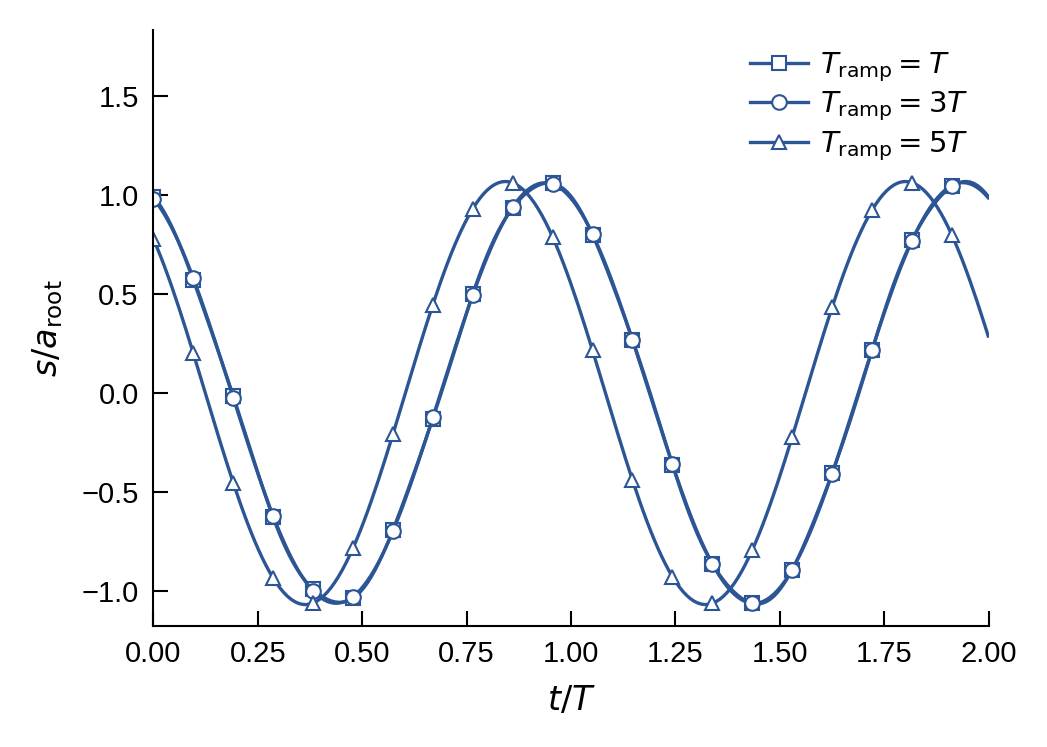

In [3]:
# Same plotting format and final-two-period window as the existing validation figure.
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "Liberation Sans"],
    "font.size": 7,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "legend.fontsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.linewidth": 0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

COLOR_TIP = "#2C5596"
MARKERS = ["s", "o", "^"]

fig, ax = plt.subplots(figsize=(3.5, 2.5), dpi=300)

for (label, case_data), marker in zip(data.items(), MARKERS):
    ax.plot(
        case_data["t_nd"],
        case_data["tip_nd"],
        color=COLOR_TIP,
        linestyle="-",
        linewidth=0.8,
        marker=marker,
        markevery=max(1, len(case_data["t_nd"]) // 20),
        markersize=3.5,
        markeredgewidth=0.5,
        markerfacecolor="white",
        label=label,
    )

ax.set_xlabel(r"$t/T$")
ax.set_ylabel(r"$s/a_{\mathrm{root}}$")

# Exactly the same two-period axis used in the original validation plot.
ax.set_xlim(0, 2)

# Same axis styling as the original compact validation figure.
y_min, y_max = ax.get_ylim()
ax.set_ylim(y_min, y_max + (y_max - y_min) * 0.28)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)

ax.legend(
    frameon=False,
    loc="upper right",
    handletextpad=0.4,
    labelspacing=0.2,
    borderaxespad=0.3,
)

fig.tight_layout()

FIG_DIR = Path.cwd() / "plots"
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(
    FIG_DIR / "tip_displacement_ramp_duration_sweep.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

plt.show()
